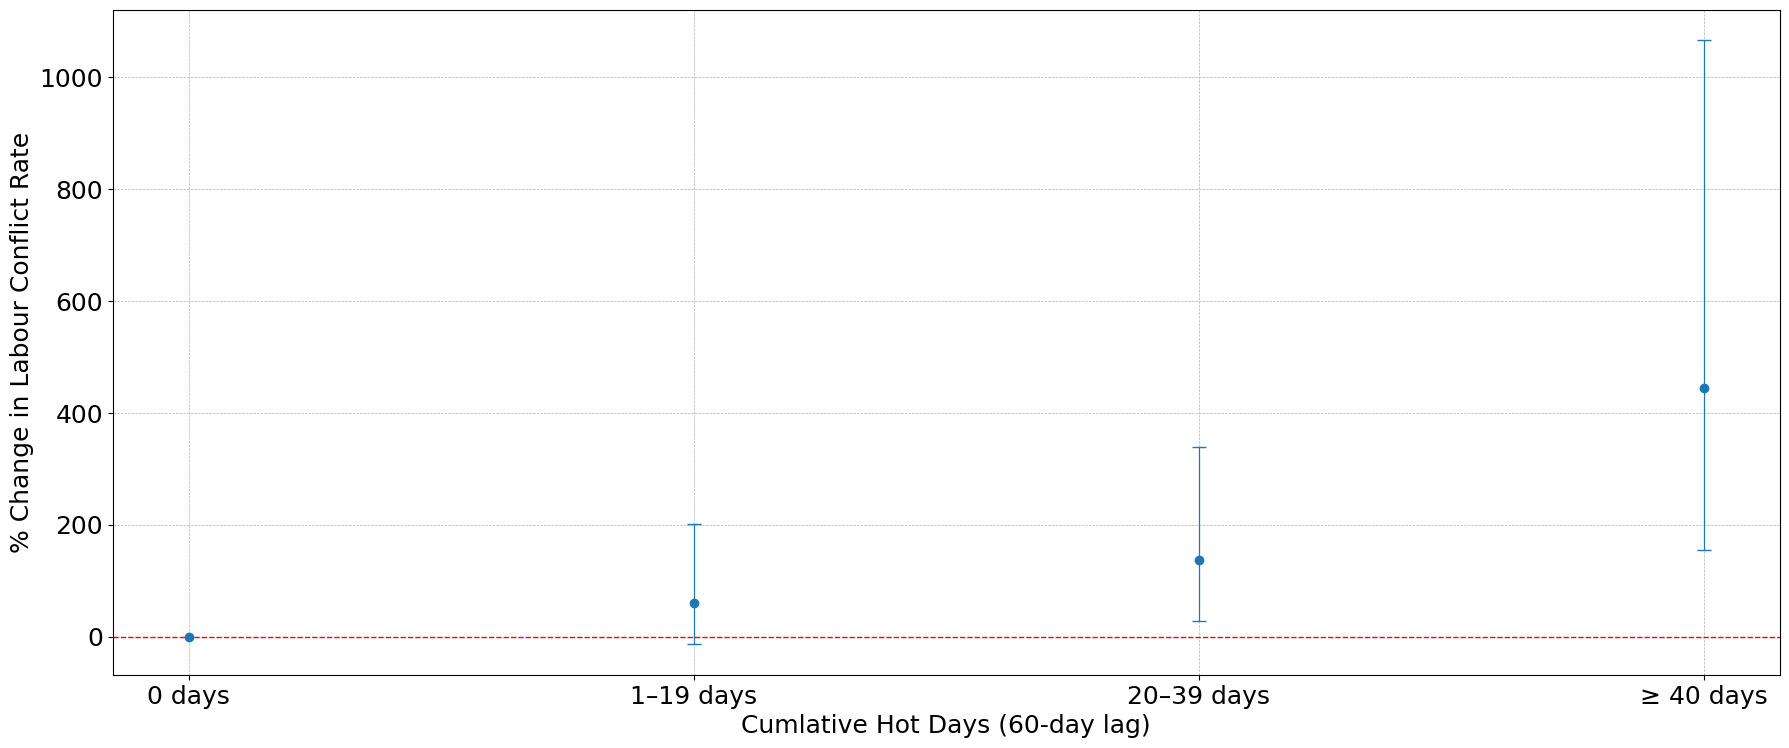

In [ ]:
# Main Figure for Presentation
import os
from tkinter import font
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Toggle ───────────────────────────────────────────────────────────────────
PERCENT = True  # True = (exp(β) - 1) * 100, False = raw coefficients

# ── Directories and Files────────────────────────────────────────────────────
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"
file = directory + r"\baseline_labour_unrest_18052026.csv"

# Lag, Contemporaneous and Lead Results
baseline = pd.read_csv(os.path.join(directory, "Raw", "Baseline", "bin_M1_labour_unrest.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

baseline = clean_df(baseline)

# Generating CI bounds
# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "20–39 days",
    "≥ 40 days",
]

# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

baseline = add_ci(baseline)

# Transform to percentage changes: (exp(β) - 1) * 100
# Transform CI bounds directly (monotonic), not the SE
def to_percent(df):
    df = df.copy()
    for col in ["est", "ci_low", "ci_high"]:
        df[col] = (np.exp(df[col]) - 1) * 100
    return df

if PERCENT:
    baseline = to_percent(baseline)

x = np.arange(len(x_labels))

# -----------------------------
# PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 10))

# Strikes (left)
ax.errorbar(
    x,
    baseline["est"],
    yerr=[
        baseline["est"] - baseline["ci_low"],
        baseline["ci_high"] - baseline["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="baseline",
)

ax.axhline(0, linestyle="--", linewidth=1, color="red")
ax.grid(True, linestyle="--", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=18)
ax.tick_params(axis='both', labelsize=18)
ax.set_xlabel("Cumulative Hot Days (60-day lag)", fontsize=18)
ax.set_ylabel("% Change in Labour Conflict Rate" if PERCENT else "Coefficient", fontsize=18)
ax.set_title("")

figurename = "baseline_pct.png" if PERCENT else "baseline.png"
plt.tight_layout()
plt.subplots_adjust(bottom=0.32)
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")

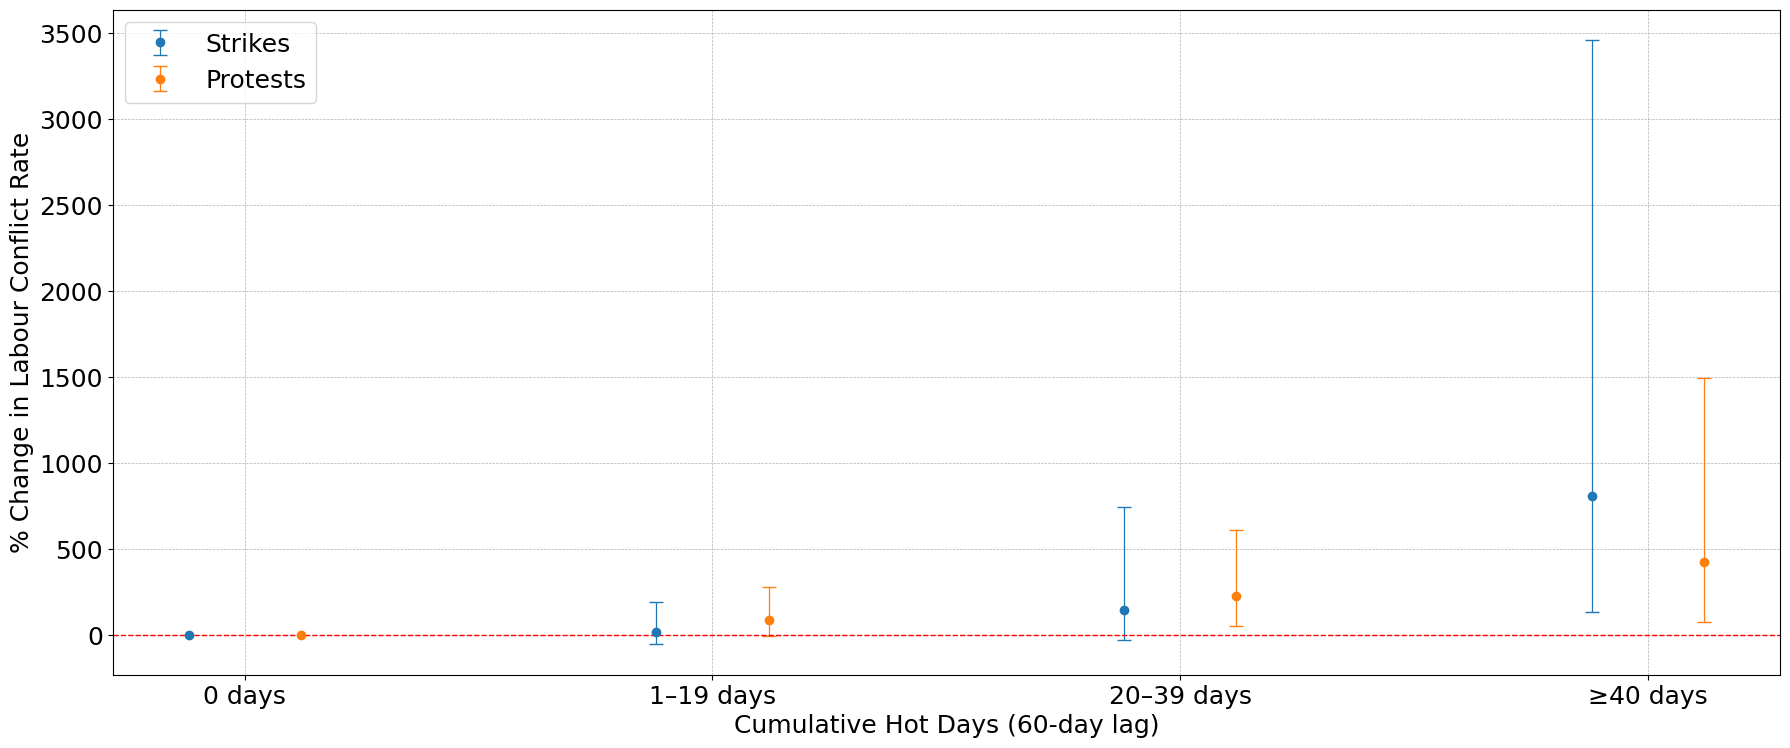

In [4]:
#########################################
###### Hetro: Action Type (Figure) ######
#########################################
#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ── Toggle ───────────────────────────────────────────────────────────────────
PERCENT = True  # True = (exp(β) - 1) * 100, False = raw coefficients

# Directory
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"

# Lag, Contemporaneous and Lead Results
strike = pd.read_csv(os.path.join(directory, "Raw", "Type", "baseline_strike_18052026.csv"))
protest = pd.read_csv(os.path.join(directory, "Raw", "Type", "baseline_protest_18052026.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

strike = clean_df(strike)
protest = clean_df(protest)

# Generating CI bounds
# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "20–39 days",
    "≥40 days",
]

# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

strike  = add_ci(strike)
protest = add_ci(protest)

# Transform to percentage changes: (exp(β) - 1) * 100
# Transform CI bounds directly (monotonic), not the SE
def to_percent(df):
    df = df.copy()
    for col in ["est", "ci_low", "ci_high"]:
        df[col] = (np.exp(df[col]) - 1) * 100
    return df

if PERCENT:
    strike  = to_percent(strike)
    protest = to_percent(protest)

x = np.arange(len(x_labels))
offset = 0.12

# -----------------------------
# PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 10))

# Strikes (left)
ax.errorbar(
    x - offset,
    strike["est"],
    yerr=[
        strike["est"] - strike["ci_low"],
        strike["ci_high"] - strike["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Strikes",
)

# Protests (right)
ax.errorbar(
    x + offset,
    protest["est"],
    yerr=[
        protest["est"] - protest["ci_low"],
        protest["ci_high"] - protest["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Protests",
)

ax.axhline(0, linestyle="--", linewidth=1, color="red")
ax.grid(True, linestyle="--", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.set_xlabel("Cumulative Hot Days (60-day lag)", fontsize=18)
ax.set_ylabel("% Change in Labour Conflict Rate" if PERCENT else "Coefficient", fontsize=18)
ax.set_title("")
ax.legend(fontsize=18)

''' 
# -----------------------------
# STATS TABLE — LaTeX Style
# -----------------------------
stats = {
    "": ["Mean dep. var.", "# Obs.", "# Counties"],
    "Strikes": ["0.0410", "90,160", "196"],
    "Protests": ["0.0546", "114,080", "248"],
}
stats_df = pd.DataFrame(stats)
# Use LaTeX rendering
plt.rcParams.update({
    "text.usetex": False,          # Set True if you have a LaTeX installation
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
})
table = ax.table(
    cellText=stats_df.values,
    colLabels=stats_df.columns,
    cellLoc="center",
    loc="bottom",
    bbox=[0, -0.35, 1, 0.24],
)
table.auto_set_font_size(False)
table.set_fontsize(9)
# ---- Style all cells ----
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("none")          # Remove all borders by default
    cell.set_facecolor("none")          # Transparent background
    # Top rule (above header)
    if row == 0:
        cell.visible_edges = "T"
        cell.set_edgecolor("black")
        cell.set_text_props(fontweight="bold")
    # Line below header
    if row == 1:
        cell.visible_edges = "T"
        cell.set_edgecolor("black")
    # Bottom rule (after last data row)
    if row == len(stats_df):
        cell.visible_edges = "B"
        cell.set_edgecolor("black")
    # Left-align the row label column
    if col == 0:
        cell.set_text_props(ha="left")
'''

figurename = "Action_type_pct.png" if PERCENT else "Action_type.png"
plt.tight_layout()
plt.subplots_adjust(bottom=0.32)
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")
plt.show()

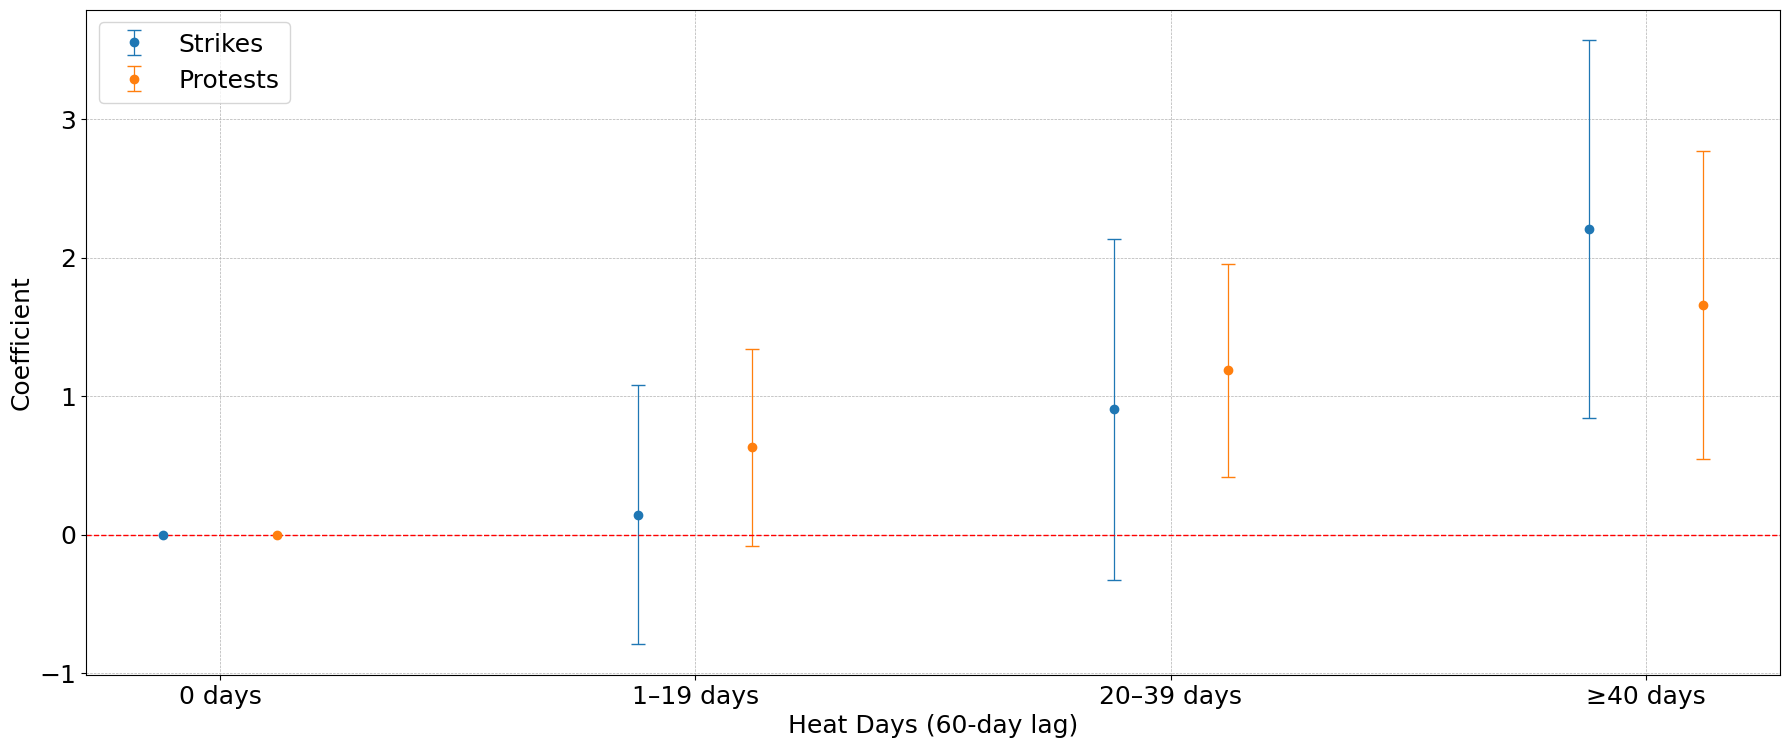

In [8]:
#########################################
###### Hetro: Action Type (Figure) ######
#########################################
#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Directory
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"

# Lag, Contemporaneous and Lead Results
strike = pd.read_csv(os.path.join(directory, "Raw", "Type", "baseline_strike_18052026.csv"))
protest = pd.read_csv(os.path.join(directory, "Raw", "Type", "baseline_protest_18052026.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


strike = clean_df(strike)
protest = clean_df(protest)

# Generating CI bounds
# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "20–39 days",
    "≥40 days",
]


# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

strike  = add_ci(strike)
protest = add_ci(protest)

x = np.arange(len(x_labels))
offset = 0.12




# -----------------------------
# PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 10))

# Strikes (left)
ax.errorbar(
    x - offset,
    strike["est"],
    yerr=[
        strike["est"] - strike["ci_low"],
        strike["ci_high"] - strike["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Strikes",
)

# Protests (right)
ax.errorbar(
    x + offset,
    protest["est"],
    yerr=[
        protest["est"] - protest["ci_low"],
        protest["ci_high"] - protest["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Protests",
)

ax.axhline(0, linestyle="--", linewidth=1, color="red")
ax.grid(True, linestyle="--", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.set_xlabel("Heat Days (60-day lag)", fontsize=18)
ax.set_ylabel("Coefficient", fontsize=18)
ax.set_title("")
ax.legend(fontsize=18)
''' 
# -----------------------------
# STATS TABLE — LaTeX Style
# -----------------------------
stats = {
    "": ["Mean dep. var.", "# Obs.", "# Counties"],
    "Strikes": ["0.0410", "90,160", "196"],
    "Protests": ["0.0546", "114,080", "248"],
}

stats_df = pd.DataFrame(stats)

# Use LaTeX rendering
plt.rcParams.update({
    "text.usetex": False,          # Set True if you have a LaTeX installation
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
})

table = ax.table(
    cellText=stats_df.values,
    colLabels=stats_df.columns,
    cellLoc="center",
    loc="bottom",
    bbox=[0, -0.35, 1, 0.24],
)

table.auto_set_font_size(False)
table.set_fontsize(9)

# ---- Style all cells ----
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("none")          # Remove all borders by default
    cell.set_facecolor("none")          # Transparent background

    # Top rule (above header)
    if row == 0:
        cell.visible_edges = "T"
        cell.set_edgecolor("black")
        cell.set_text_props(fontweight="bold")

    # Line below header
    if row == 1:
        cell.visible_edges = "T"
        cell.set_edgecolor("black")

    # Bottom rule (after last data row)
    if row == len(stats_df):
        cell.visible_edges = "B"
        cell.set_edgecolor("black")

    # Left-align the row label column
    if col == 0:
        cell.set_text_props(ha="left")

'''

figurename = "Action_type.png"
plt.tight_layout()
plt.subplots_adjust(bottom=0.32)
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")
plt.show()

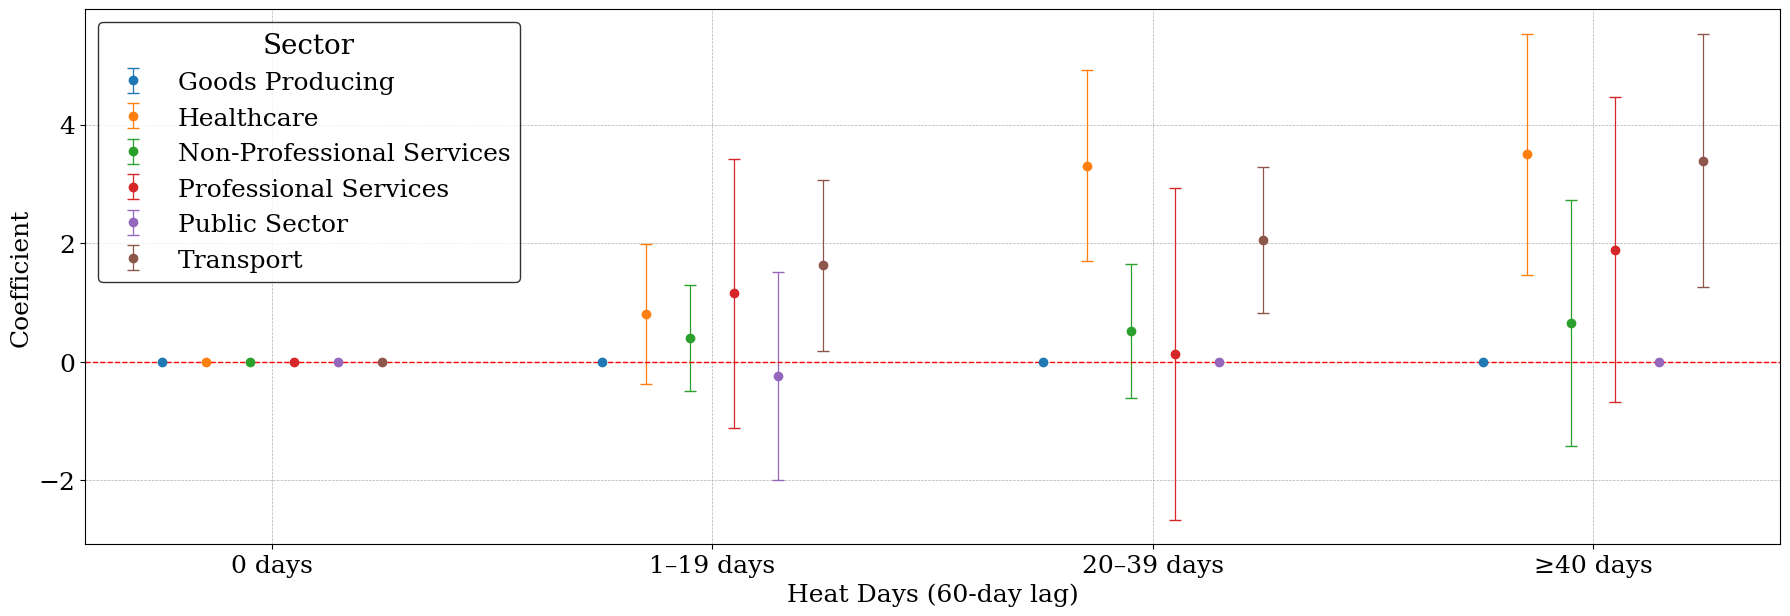

In [12]:
#########################################
###### Hetro: Action Type (Figure) ######
#########################################
#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Directory
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"

# Industry Results
goods_producing = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_goods_producing_18052026.csv"))
healthcare = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_healthcare_18052026.csv"))
non_professional_services = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_non_professional_s_18052026.csv"))
professional_services = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_professional_servi_18052026.csv"))
public_sector = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_public_sector_18052026.csv"))
transport = pd.read_csv(os.path.join(directory, "Raw", "Industry", "baseline_labour_unrest_transport_18052026.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


goods_producing = clean_df(goods_producing)
healthcare = clean_df(healthcare)
non_professional_services = clean_df(non_professional_services)
professional_services = clean_df(professional_services)
public_sector = clean_df(public_sector)
transport = clean_df(transport)

# Generating CI bounds
# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "20–39 days",
    "≥40 days",
]


# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

goods_producing  = add_ci(goods_producing)
healthcare = add_ci(healthcare)
non_professional_services = add_ci(non_professional_services)
professional_services = add_ci(professional_services)
public_sector = add_ci(public_sector)
transport = add_ci(transport)

x = np.arange(len(x_labels))
offset = 0.12

# -----------------------------
# SETTINGS
# -----------------------------
sectors = {
    "Goods Producing":           {"data": goods_producing,           "color": "#1f77b4"},
    "Healthcare":                {"data": healthcare,                 "color": "#ff7f0e"},
    "Non-Professional Services": {"data": non_professional_services,  "color": "#2ca02c"},
    "Professional Services":     {"data": professional_services,      "color": "#d62728"},
    "Public Sector":             {"data": public_sector,              "color": "#9467bd"},
    "Transport":                 {"data": transport,                  "color": "#8c564b"},
}

# Offsets so points don't overlap on the x-axis
n_sectors = len(sectors)
offsets = np.linspace(-0.25, 0.25, n_sectors)

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
})

# -----------------------------
# PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 10))

for (sector_name, sector_info), offset in zip(sectors.items(), offsets):
    df  = sector_info["data"]
    col = sector_info["color"]

    ax.errorbar(
        x + offset,
        df["est"],
        yerr=[
            df["est"] - df["ci_low"],
            df["ci_high"] - df["est"],
        ],
        fmt="o",
        capsize=4,
        linewidth=0.9,
        color=col,
        label=sector_name,
    )

ax.axhline(0, linestyle="--", linewidth=1, color="red")
ax.grid(True, linestyle="--", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.set_xlabel("Heat Days (60-day lag)", fontsize=18)
ax.set_ylabel("Coefficient", fontsize=18)
ax.set_title("")
ax.legend(
    title="Sector",
    fontsize=18,
    title_fontsize=20,
    frameon=True,
    edgecolor="black",
    loc="upper left",
)

figurename = "Sector_level.png"
plt.tight_layout()
plt.subplots_adjust(bottom=0.45)    # increase if table is cut off
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")
plt.show()

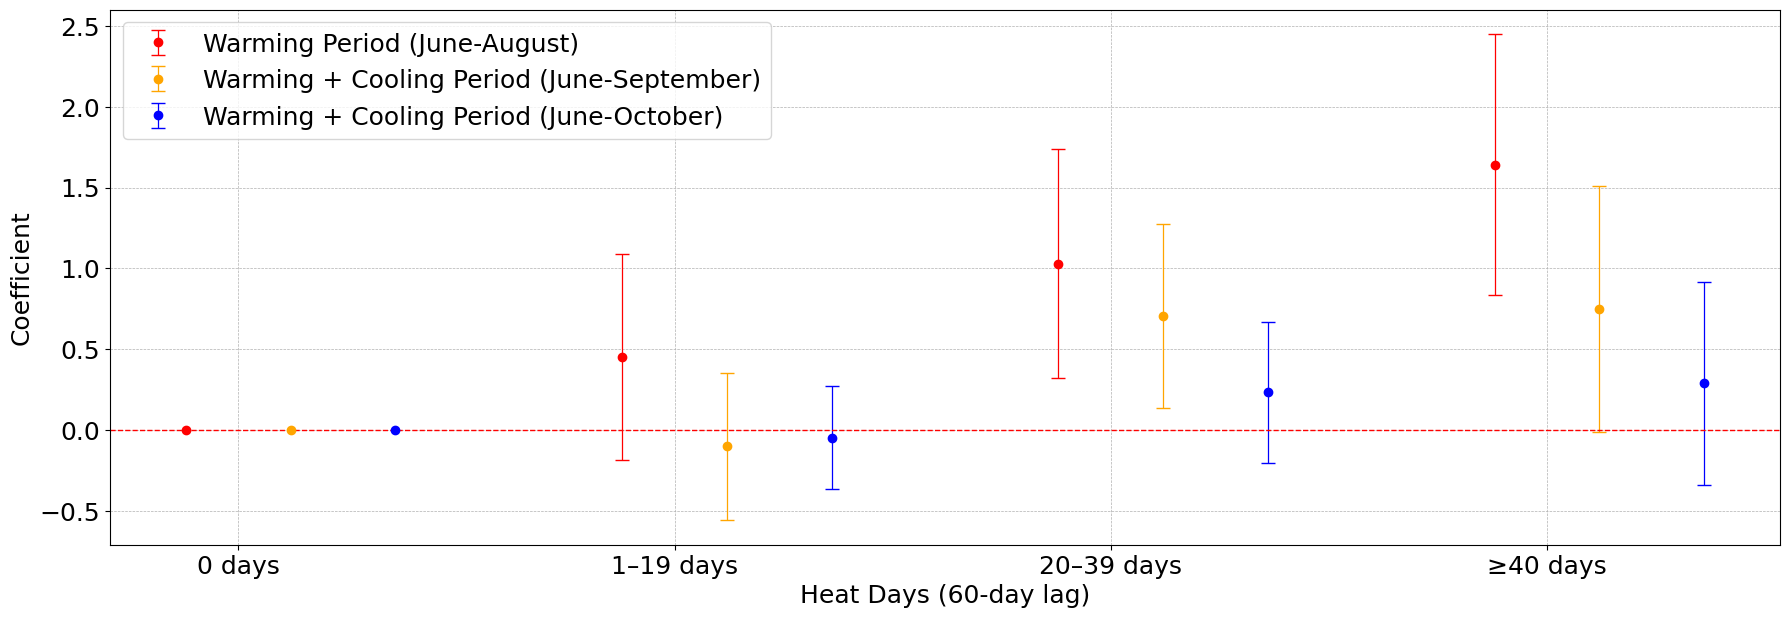

In [1]:
###########################################
###### Extending the Summer Period  ######
###########################################
#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Directory
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"

# Lag, Contemporaneous and Lead Results
warming = pd.read_csv(os.path.join(directory, "Raw", "Period", "summer_labour_unrest_18052026.csv"))
warming_cooling_1 = pd.read_csv(os.path.join(directory, "Raw", "Period", "summer_extn1_labour_unrest_18052026.csv"))
warming_cooling_2 = pd.read_csv(os.path.join(directory, "Raw", "Period", "summer_extn2_labour_unrest_18052026.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df

warming = clean_df(warming)
warming_cooling_1 = clean_df(warming_cooling_1)
warming_cooling_2 = clean_df(warming_cooling_2)

# Generating CI bounds
# X-axis labels in the order you described
x_labels = [
    "0 days",
    "1–19 days",
    "20–39 days",
    "≥40 days",
]

# Figure (Strikes and Protests)
x = np.arange(len(x_labels))

def add_ci(df, est_col="est", se_col="se"):
    df = df.copy()
    df["ci_low"]  = df[est_col] - 1.96 * df[se_col]
    df["ci_high"] = df[est_col] + 1.96 * df[se_col]
    return df

warming  = add_ci(warming)
warming_cooling_1 = add_ci(warming_cooling_1)
warming_cooling_2 = add_ci(warming_cooling_2)

x = np.arange(len(x_labels))
offset = 0.12

# -----------------------------
# PLOT
# -----------------------------
fig, ax = plt.subplots(figsize=(18, 10))

# Warming Period (June-August)
ax.errorbar(
    x - offset,
    warming["est"],
    yerr=[
        warming["est"] - warming["ci_low"],
        warming["ci_high"] - warming["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Warming Period (June-August)",
    color="red",
)

# Warming + Cooling (1st extension) 
ax.errorbar(
    x + offset,
    warming_cooling_1["est"],
    yerr=[
        warming_cooling_1["est"] - warming_cooling_1["ci_low"],
        warming_cooling_1["ci_high"] - warming_cooling_1["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Warming + Cooling Period (June-September)",
    color="orange",
)

# Warming + Cooling (2nd extension)
ax.errorbar(
    x + (offset * 3),
    warming_cooling_2["est"],
    yerr=[
        warming_cooling_2["est"] - warming_cooling_2["ci_low"],
        warming_cooling_2["ci_high"] - warming_cooling_2["est"],
    ],
    fmt="o", capsize=5, linewidth=0.9, label="Warming + Cooling Period (June-October)",
    color="blue"
)


ax.axhline(0, linestyle="--", linewidth=1, color="red")
ax.grid(True, linestyle="--", linewidth=0.5)
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=18)
ax.tick_params(axis='y', labelsize=18)
ax.set_xlabel("Heat Days (60-day lag)", fontsize=18)
ax.set_ylabel("Coefficient", fontsize=18)
ax.set_title("")
ax.legend(fontsize=18)

figurename = "Study_period.png"
plt.tight_layout()
plt.subplots_adjust(bottom=0.45)    # increase if table is cut off
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")
plt.show()

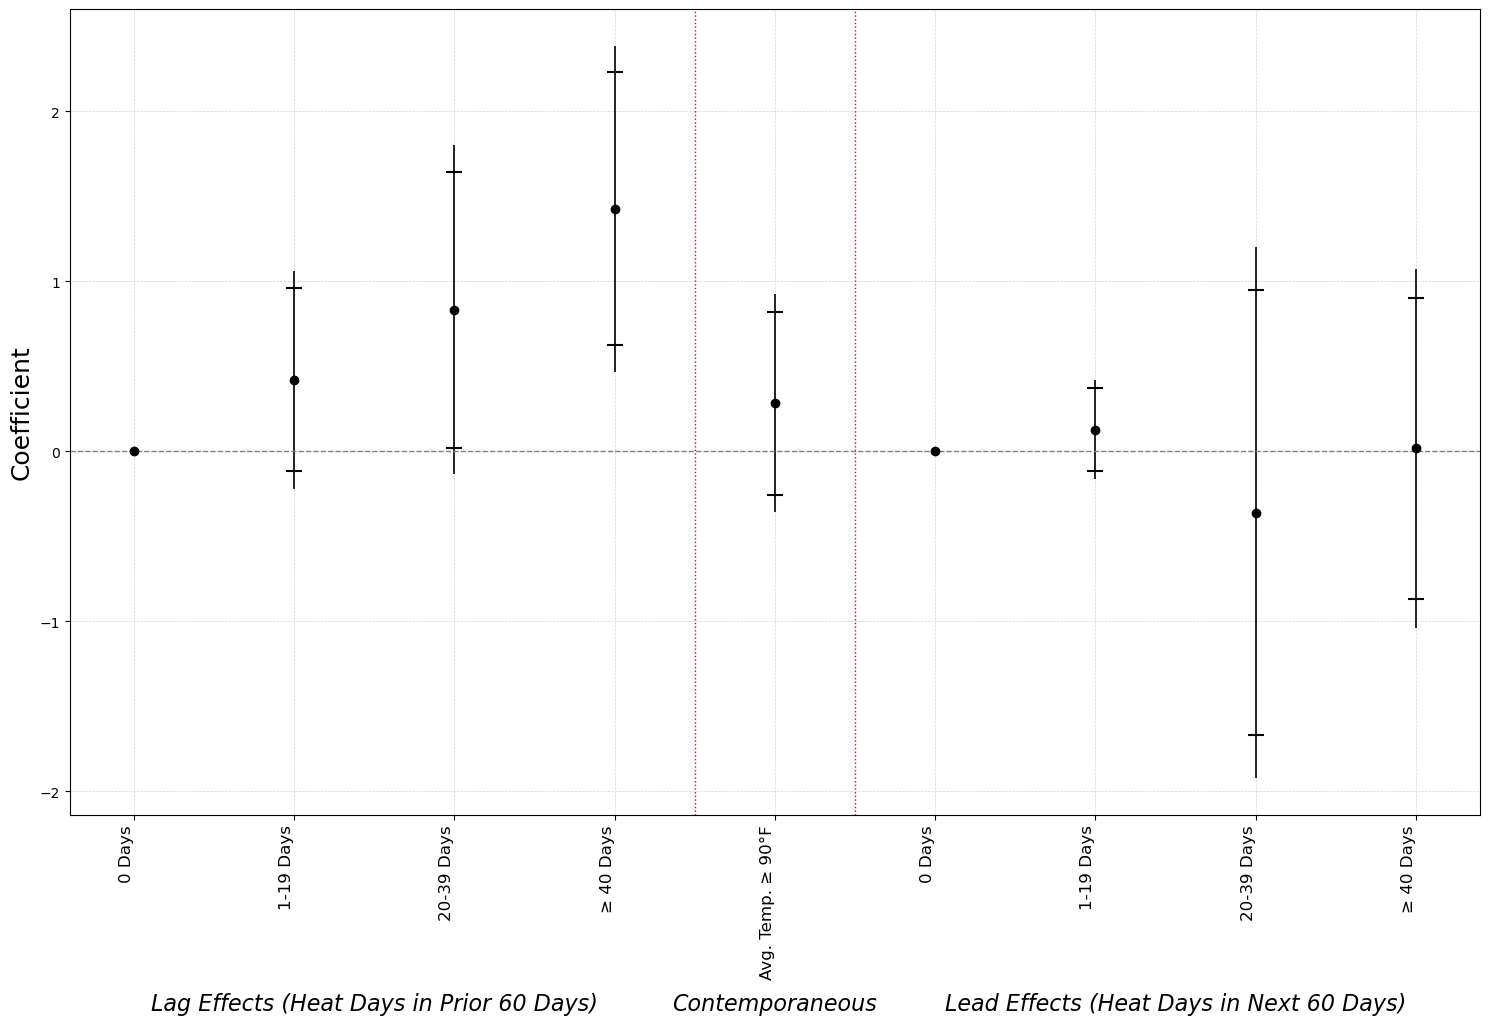

In [10]:
############################################################
###### Lag, Contemporaneous and Lead Results (Figure) ######
############################################################

#Packages
import os
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Directory
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)\Raw"

# Lag, Contemporaneous and Lead Results
lc_lead = pd.read_csv(os.path.join(directory, "Leads", "baseline_lead.csv"))

def clean_df(df):
    # Rename columns
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        "m1": "est",
        "Unnamed: 2": "se"
    })
    
    # Keep only the second row
    df = df.iloc[1:10].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


lc_lead = clean_df(lc_lead)

# ============================================================
df = lc_lead  
# ============================================================

var_order = [
    "0.num_above_90_60d",
    "1.num_above_90_60d",
    "2.num_above_90_60d",
    "3.num_above_90_60d",
    "nn_tavg_above_90",
    "0.num_above_90_60d_lead",
    "1.num_above_90_60d_lead",
    "2.num_above_90_60d_lead",
    "3.num_above_90_60d_lead",
]

x_labels = [
    "0 Days", "1-19 Days", "20-39 Days", "≥ 40 Days",
    "Avg. Temp. ≥ 90°F",
    "0 Days", "1-19 Days", "20-39 Days", "≥ 40 Days",
]

plot_df = (
    df[df["Variable"].isin(var_order)]
    .set_index("Variable")
    .loc[var_order]
    .copy()
)

# 95% CI
plot_df["ci_low_95"]  = plot_df["est"] - 1.96 * plot_df["se"]
plot_df["ci_high_95"] = plot_df["est"] + 1.96 * plot_df["se"]

# 90% CI
plot_df["ci_low_90"]  = plot_df["est"] - 1.645 * plot_df["se"]
plot_df["ci_high_90"] = plot_df["est"] + 1.645 * plot_df["se"]

x = np.arange(len(var_order))

# -------------------- PLOTTING --------------------
fig, ax = plt.subplots(figsize=(15, 10))

# 95% CI — thin vertical line
ax.errorbar(
    x,
    plot_df["est"],
    yerr=[
        plot_df["est"] - plot_df["ci_low_95"],
        plot_df["ci_high_95"] - plot_df["est"],
    ],
    fmt="none",
    capsize=0,
    linewidth=1.2,
    ecolor="black",
    label="95% CI",
)

# 90% CI — horizontal dashes as caps
ax.errorbar(
    x,
    plot_df["est"],
    yerr=[
        plot_df["est"] - plot_df["ci_low_90"],
        plot_df["ci_high_90"] - plot_df["est"],
    ],
    fmt="none",
    capsize=6,
    capthick=1.5,
    linewidth=0,
    ecolor="black",
    label="90% CI",
)

ax.scatter(x, plot_df["est"], color="black", zorder=3)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.axvline(3.5, color="red", linestyle=":", linewidth=1)
ax.axvline(4.5, color="red", linestyle=":", linewidth=1)

ax.grid(True, linestyle="--", linewidth=0.5, color="lightgrey")

ax.set_xticks(x)
ax.set_xticklabels(x_labels, rotation=90, ha="right", fontsize=12)
ax.set_ylabel("Coefficient", fontsize=18)

# Adjust bottom margin to make room for sub-headings
fig.subplots_adjust(bottom=0.25)

# x-positions: midpoint of lag group (0-3), contemp (4), lead group (5-8)
ax.text(1.5, -0.22, "Lag Effects (Heat Days in Prior 60 Days)",
        ha="center", va="top", transform=ax.get_xaxis_transform(),
        fontsize=16, fontstyle="italic")

ax.text(4, -0.22, "Contemporaneous",
        ha="center", va="top", transform=ax.get_xaxis_transform(),
        fontsize=16, fontstyle="italic")

ax.text(6.5, -0.22, "Lead Effects (Heat Days in Next 60 Days)",
        ha="center", va="top", transform=ax.get_xaxis_transform(),
        fontsize=16, fontstyle="italic")


from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="black", linewidth=1.2, label="95% CI"),
    Line2D([0], [0], color="black", linewidth=0, marker="|", markersize=10,
           markeredgewidth=1.5, label="90% CI"),
]
#ax.legend(handles=legend_elements, frameon=False)

plt.tight_layout()
figurename = "Baseline_lag_contemp_lead.png"
plt.savefig(os.path.join(directory, figurename), dpi=300, bbox_inches="tight")
plt.show()


Absolute maximum DFBETA per category (normalised by full-sample SE):
          category  max_abs_dfbeta fips_at_max  beta_full  se_full  beta_drop_fips  delta_beta
3.num_above_90_60d        0.573085        6025      1.694    0.389        1.916930    0.222930
2.num_above_90_60d        0.540070       48453      0.862    0.315        1.032122    0.170122
1.num_above_90_60d        0.423982       48453      0.473    0.320        0.608674    0.135674


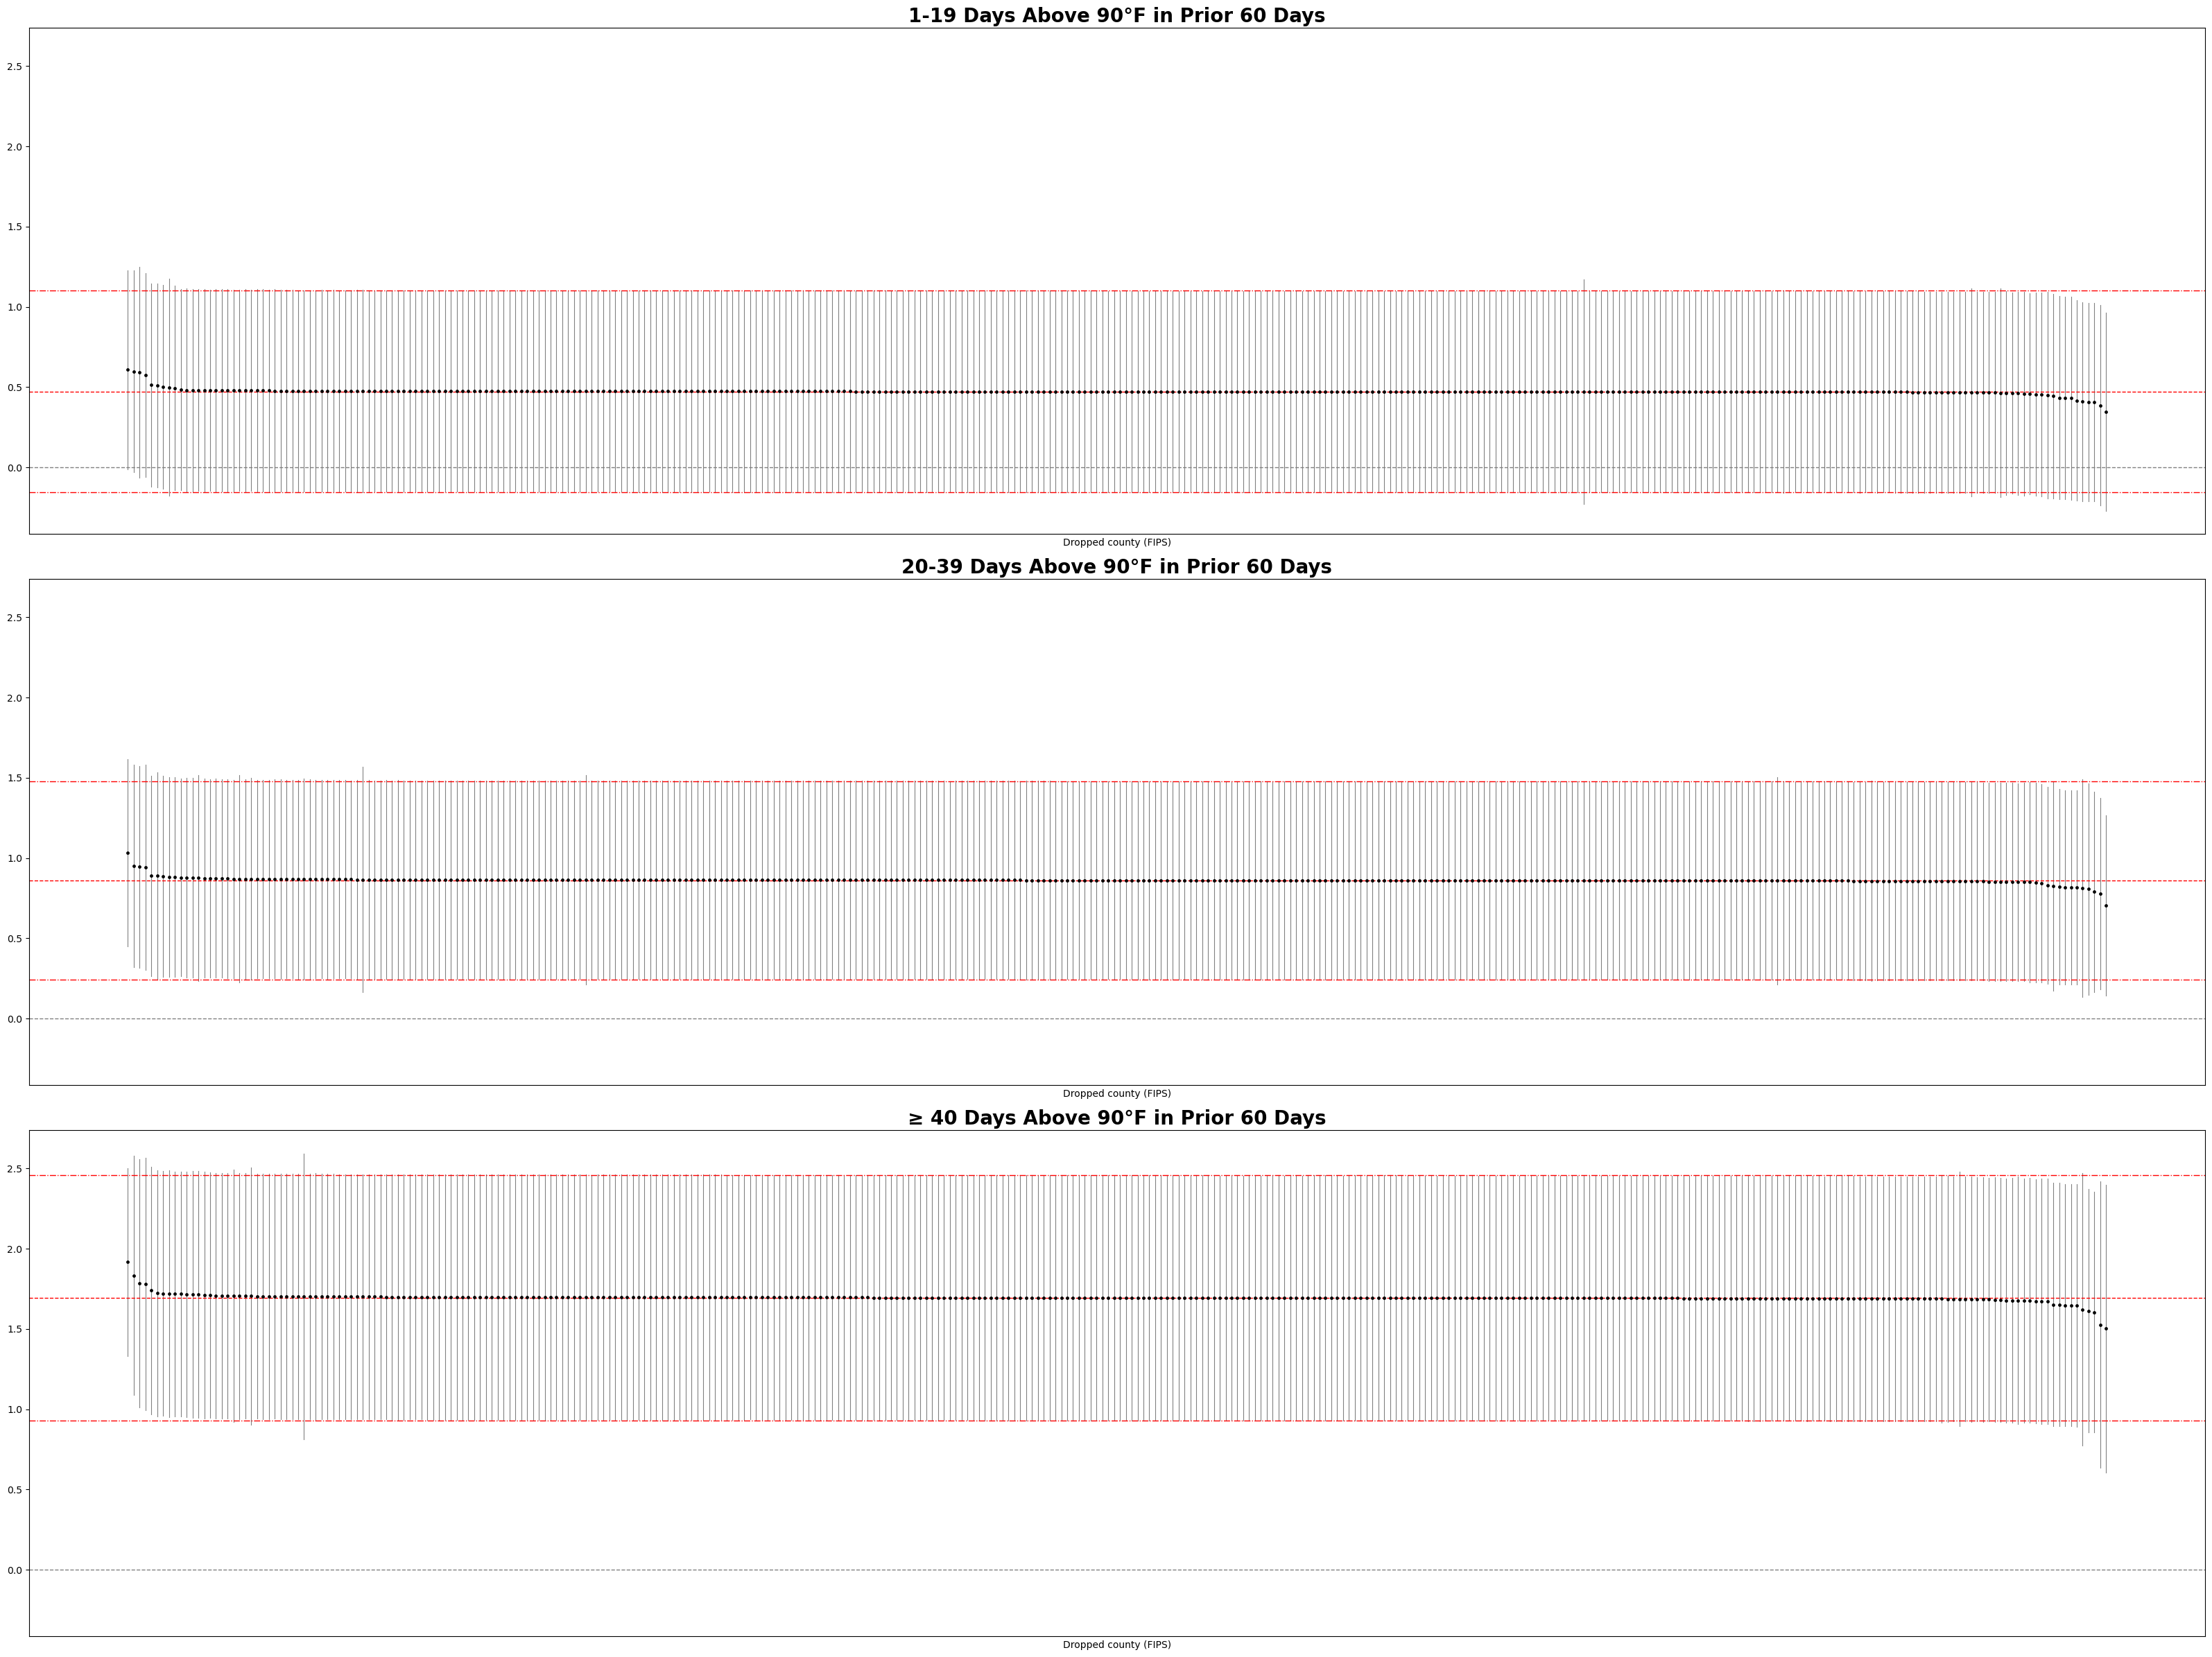

In [13]:
###############################################
###### Influential Observations (Figure) ######
###############################################

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# USER SETTINGS
# -----------------------------
county_in_out_directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)\Raw\Influental"
output_dir = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"
os.makedirs(output_dir, exist_ok=True)

figurename = "FIPS_Inout_3panel.png"

# Put your THREE category names here (must match what appears in the CSV 'Variable' column)
CATEGORIES = [
    "1.num_above_90_60d",  # e.g. "num_above_90_60d"
    "2.num_above_90_60d",  # e.g. "num_above_90_60d"
    "3.num_above_90_60d",  # e.g. "num_above_95_60d"
]

# Category-specific full-sample ("original") estimates and standard errors
# Fill in the est/se for each category.
ORIG_STATS = {
    "1.num_above_90_60d": {"est": 0.473, "se": 0.320},
    "2.num_above_90_60d": {"est": 0.862, "se": 0.315},
    "3.num_above_90_60d": {"est": 1.694, "se": 0.389},
}

# If the category labels aren't reliable, force selection by row number:
# You said relevant rows are 4, 5, 6 (1-indexed) -> indices 3, 4, 5 (0-indexed)
ROW_MAP = {
    CATEGORIES[0]: 3,  # row 4
    CATEGORIES[1]: 4,  # row 5
    CATEGORIES[2]: 5,  # row 6
}


# -----------------------------
# HELPERS
# -----------------------------
def standardise_regression_table(df: pd.DataFrame) -> pd.DataFrame:
    """
    Standardise typical regression CSV export format:
    - rename columns to Variable, est, se
    - clean est/se into numeric
    """
    df = df.rename(columns={
        "Unnamed: 0": "Variable",
        ".": "est",
        "Unnamed: 2": "se"
    })

    if "Variable" not in df.columns:
        raise ValueError("Could not find/rename a 'Variable' column. Check CSV structure/headers.")
    if "est" not in df.columns or "se" not in df.columns:
        raise ValueError("Could not find/rename 'est' and 'se' columns. Check CSV structure/headers.")

    df["est"] = (
        df["est"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )
    df["se"] = (
        df["se"].astype(str)
        .str.replace(r"[()]", "", regex=True)
        .str.strip()
    )

    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"] = pd.to_numeric(df["se"], errors="coerce")
    return df


def extract_fips_from_filename(filename: str) -> str:
    """
    Extract FIPS from filename by taking final underscore chunk before extension.
    Example: something_anything_17031.csv -> 17031
    """
    stem = os.path.splitext(os.path.basename(filename))[0]
    return stem.split("_")[-1]


def select_row_for_category(df: pd.DataFrame, category: str) -> pd.DataFrame:
    """
    Select the row for the category.
    First try exact match on Variable; if not found, force by row index using ROW_MAP.
    """
    # Try exact match first
    if category in df["Variable"].values:
        return df[df["Variable"] == category].copy().reset_index(drop=True)

    # Force by known row position (row 4/5/6 etc.)
    if category in ROW_MAP:
        idx = ROW_MAP[category]
        if idx < 0 or idx >= len(df):
            raise IndexError(
                f"ROW_MAP index {idx} out of bounds for category '{category}' "
                f"in this file (len={len(df)})."
            )
        out = df.iloc[[idx]].copy()
        out["Variable"] = category  # label it consistently for downstream steps
        return out.reset_index(drop=True)

    # If neither works, fail loudly (better than silently wrong)
    raise KeyError(
        f"Could not find category '{category}' in Variable column, and no ROW_MAP entry exists."
    )


def add_ci95(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ci95_low"] = df["est"] - 1.96 * df["se"]
    df["ci95_high"] = df["est"] + 1.96 * df["se"]
    return df


def get_orig_lines_for_category(cat: str):
    """
    Return (orig_est, orig_ci95_low, orig_ci95_high) for a category.
    """
    if cat not in ORIG_STATS:
        raise KeyError(f"Category '{cat}' is missing from ORIG_STATS.")

    est = ORIG_STATS[cat]["est"]
    se = ORIG_STATS[cat]["se"]
    ci_low = est - 1.96 * se
    ci_high = est + 1.96 * se
    return est, ci_low, ci_high

CATEGORY_LABELS = {
    "1.num_above_90_60d": "1-19 Days Above 90°F in Prior 60 Days",
    "2.num_above_90_60d": "20-39 Days Above 90°F in Prior 60 Days",
    "3.num_above_90_60d": "≥ 40 Days Above 90°F in Prior 60 Days",
}

# -----------------------------
# READ + BUILD CATEGORY DATAFRAMES
# -----------------------------
cat_to_rows = {cat: [] for cat in CATEGORIES}

for fname in os.listdir(county_in_out_directory):
    if not fname.endswith(".csv"):
        continue

    fpath = os.path.join(county_in_out_directory, fname)
    fips = extract_fips_from_filename(fname)

    raw = pd.read_csv(fpath)
    tbl = standardise_regression_table(raw)

    for cat in CATEGORIES:
        one = select_row_for_category(tbl, cat)
        one["fips"] = fips
        one = add_ci95(one)

        one = one[["Variable", "est", "se", "ci95_low", "ci95_high", "fips"]].copy()
        cat_to_rows[cat].append(one)

cat_to_df = {}
for cat in CATEGORIES:
    if len(cat_to_rows[cat]) == 0:
        cat_to_df[cat] = pd.DataFrame(columns=["Variable", "est", "se", "ci95_low", "ci95_high", "fips"])
    else:
        cat_to_df[cat] = pd.concat(cat_to_rows[cat], ignore_index=True)

# -----------------------------
# DFBETAs: absolute maximum per category
# -----------------------------
dfbeta_summary = []

for cat in CATEGORIES:
    if cat not in ORIG_STATS:
        raise KeyError(f"Category '{cat}' missing from ORIG_STATS.")

    full_est = ORIG_STATS[cat]["est"]
    full_se  = ORIG_STATS[cat]["se"]

    if full_se is None or pd.isna(full_se) or full_se == 0:
        raise ValueError(
            f"Full-sample SE for category '{cat}' is {full_se}. "
            "DFBETAs require a non-zero SE in ORIG_STATS."
        )

    df_cat = cat_to_df[cat].dropna(subset=["est", "fips"]).copy()

    # DFBETA_i = (beta_-i - beta_full) / SE_full
    df_cat["dfbeta"] = (df_cat["est"] - full_est) / full_se
    df_cat["abs_dfbeta"] = df_cat["dfbeta"].abs()

    # Absolute maximum
    idx = df_cat["abs_dfbeta"].idxmax()
    max_row = df_cat.loc[idx]

    dfbeta_summary.append({
        "category": cat,
        "max_abs_dfbeta": float(max_row["abs_dfbeta"]),
        "fips_at_max": str(max_row["fips"]),
        "beta_full": float(full_est),
        "se_full": float(full_se),
        "beta_drop_fips": float(max_row["est"]),
        "delta_beta": float(max_row["est"] - full_est),
    })

dfbeta_summary_df = pd.DataFrame(dfbeta_summary).sort_values("max_abs_dfbeta", ascending=False)

print("\nAbsolute maximum DFBETA per category (normalised by full-sample SE):")
print(dfbeta_summary_df.to_string(index=False))

# -----------------------------
# PLOT: 3 SUBPLOTS
# -----------------------------
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(32, 24), sharey=True)

for ax, cat in zip(axes, CATEGORIES):
    df_cat = cat_to_df[cat].dropna(subset=["est", "se"]).copy()

    # Sort within category
    df_sorted = df_cat.sort_values("est", ascending=False).reset_index(drop=True)
    x = np.arange(len(df_sorted))

    # CI vertical lines
    for i, row in df_sorted.iterrows():
        ax.plot([i, i], [row["ci95_low"], row["ci95_high"]], color="grey", linewidth=0.8)

    # Point estimates
    ax.scatter(x, df_sorted["est"], color="black", s=6, zorder=3)

    # Reference lines: category-specific original
    orig_est, orig_ci95_low, orig_ci95_high = get_orig_lines_for_category(cat)

    ax.axhline(0, linestyle="--", color="grey", linewidth=1)
    ax.axhline(orig_est, linestyle="--", color="red", linewidth=1)
    ax.axhline(orig_ci95_low, linestyle="-.", color="red", linewidth=1)
    ax.axhline(orig_ci95_high, linestyle="-.", color="red", linewidth=1)

    ax.set_title(CATEGORY_LABELS.get(cat, cat), fontsize=20, fontweight='bold')
    ax.set_xticks([])
    ax.set_xlabel("Dropped county (FIPS)")

axes[0].set_ylabel("")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, figurename), dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
###########################################################
###### Percentage and Absolute Expected Changes Table ######
############################################################

# Packages
import pandas as pd
import numpy as np
import os
from scipy import stats

# ── Directories and Folders ────────────────────────────────────────────────────
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)\Raw"
folders = ["Baseline", "Type", "Industry"]

# ── Load and Clean CSVs ────────────────────────────────────────────────────────
def clean_df(df):
    df = df.rename(columns={"Unnamed: 0": "Variable", ".": "est", "Unnamed: 2": "se"})
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"]  = pd.to_numeric(df["se"],  errors="coerce")
    return df

TARGET_SUFFIX = "_18052026"

for folder in folders:
    folder_path = os.path.join(directory, folder)
    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            stem = filename.replace(".csv", "")
            if stem.endswith(TARGET_SUFFIX):
                var_name = f"{folder}_{stem}".lower()
                globals()[var_name] = clean_df(pd.read_csv(os.path.join(folder_path, filename)))
                print(f"Created: {var_name}")

# ── Hardcoded Scalars ──────────────────────────────────────────────────────────

# Mean of the dependent variable — used for display and absolute change column only
mean_dep_var = {
    # Baseline - Continuous
    "baseline_continuous_pref":      0.0956,
    "baseline_continuous_robust":    0.1882,
    # Baseline - Bin
    "baseline_bin_pref":             0.0956,
    "baseline_bin_robust":           0.1882,
    # Type
    "strike":                        0.0410,
    "protest":                       0.0546,
    # Industry
    "good_producing":                0.0293,
    "healthcare":                    0.0113,
    "non_professional_services":     0.0163,
    "professional_services":         0.0109,
    "public_sector":                 0.0220,
    "transport":                     0.0055,
}

# Baseline event rate on non-heat days — used for attributable events calculation.
# Back-calculated as:
#   baseline_rate = total_events / (non_heat_days + IRR_bin1*n_bin1 + IRR_bin2*n_bin2 + ...)
# This is a single constant per model, not varying across bins.
# !! Replace all XXXXX placeholders with your actual back-calculated values !!
baseline_rate = {
    "baseline_pref":             0.0071,
    "baseline_robust":           0.0140,
    "strike":                    0.0049,
    "protest":                   0.0058,
    "good_producing":            0.0028,
    "healthcare":                0.0043,
    "non_professional_services": 0.0059,
    "professional_services":     0.0042,
    "public_sector":             0.0033,
    "transport":                 0.0033,
}


Created: baseline_baseline_labour_unrest_18052026
Created: type_baseline_protest_18052026
Created: type_baseline_strike_18052026
Created: industry_baseline_labour_unrest_goods_producing_18052026
Created: industry_baseline_labour_unrest_healthcare_18052026
Created: industry_baseline_labour_unrest_non_professional_s_18052026
Created: industry_baseline_labour_unrest_professional_servi_18052026
Created: industry_baseline_labour_unrest_public_sector_18052026
Created: industry_baseline_labour_unrest_transport_18052026


In [9]:
###########################################################
###### Percentage and Absolute Expected Changes Table ######
############################################################

# Packages
import pandas as pd
import numpy as np
import os
from scipy import stats

# ── Directories and Folders ────────────────────────────────────────────────────
directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)\Raw"
folders = ["Baseline", "Type", "Industry"]

# ── Load and Clean CSVs ────────────────────────────────────────────────────────
def clean_df(df):
    df = df.rename(columns={"Unnamed: 0": "Variable", ".": "est", "Unnamed: 2": "se"})
    df = df.iloc[1:5].reset_index(drop=True)
    df["est"] = pd.to_numeric(df["est"], errors="coerce")
    df["se"]  = pd.to_numeric(df["se"],  errors="coerce")
    return df

TARGET_SUFFIX = "_18052026"

for folder in folders:
    folder_path = os.path.join(directory, folder)
    for filename in os.listdir(folder_path):
        if filename.endswith(".csv"):
            stem = filename.replace(".csv", "")
            if stem.endswith(TARGET_SUFFIX):
                var_name = f"{folder}_{stem}".lower()
                globals()[var_name] = clean_df(pd.read_csv(os.path.join(folder_path, filename)))
                print(f"Created: {var_name}")

# ── Hardcoded Scalars ──────────────────────────────────────────────────────────

mean_dep_var = {
    "baseline_bin_pref":             0.0956,
    "strike":                        0.0410,
    "protest":                       0.0546,
    "good_producing":                0.0293,
    "healthcare":                    0.0113,
    "non_professional_services":     0.0163,
    "professional_services":         0.0109,
    "public_sector":                 0.0220,
    "transport":                     0.0055,
}

baseline_rate = {
    "baseline_pref":             0.0071,
    "strike":                    0.0049,
    "protest":                   0.0058,
    "good_producing":            0.0028,
    "healthcare":                0.0043,
    "non_professional_services": 0.0059,
    "professional_services":     0.0042,
    "public_sector":             0.0033,
    "transport":                 0.0033,
}

# ── Significance Stars ─────────────────────────────────────────────────────────
def get_stars(est, se):
    t = abs(est / se)
    p = 2 * (1 - stats.norm.cdf(t))
    if p < 0.01:   return "***"
    elif p < 0.05: return "**"
    elif p < 0.1:  return "*"
    else:          return ""

# ── Column Calculations ────────────────────────────────────────────────────────
def calc_row(est, se, mean_dv, base_rate, n_evt):
    stars      = get_stars(est, se)
    pct_change = (np.exp(est) - 1) * 100

    if n_evt is None:
        return {
            "Estimated Coefficient": f"{est:.4f}{stars}",
            "Pct. Change":           f"{pct_change:.4f}",
            "Baseline Incidence Rate": f"{base_rate:.4f}",
            "Incidence of Exposure": "",
            "# Attributable Events": "",
        }
    else:
        n_attr = base_rate * (np.exp(est) - 1) * n_evt

        return {
            "Estimated Coefficient": f"{est:.4f}{stars}",
            "Pct. Change":           f"{pct_change:.4f}",
            "Baseline Incidence Rate": f"{base_rate:.4f}",
            "Incidence of Exposure": f"{n_evt}",
            "# Attributable Events": f"{n_attr:.4f}",
        }

# ── Bin Labels ─────────────────────────────────────────────────────────────────
bin_labels = ["0 Days", "1-19 Days", "20-39 Days", "\geq 40 Days"]

# ── Model Specifications ───────────────────────────────────────────────────────
bin_specs = [
    # ── Baseline ──────────────────────────────────────────────────────────────
    {
        "var_name":     "baseline_baseline_labour_unrest_18052026",
        "mdv_key":      "baseline_bin_pref",
        "baseline_key": "baseline_pref",
        "section":      "Bin Measure of Heat Exposure",
        "n_evt": {
            "0 Days":     148966,
            "1-19 Days":  4684,
            "20-39 Days": 1312,
            "\geq 40 Days":   518,
        },
    },
    # ── Type ──────────────────────────────────────────────────────────────────
    {
        "var_name":     "type_baseline_strike_18052026",
        "mdv_key":      "strike",
        "baseline_key": "strike",
        "section":      "Strikes",
        "n_evt": {
            "0 Days":     86603,
            "1-19 Days":  2674,
            "20-39 Days": 635,
            "\geq 40 Days":   248,
        },
    },
    {
        "var_name":     "type_baseline_protest_18052026",
        "mdv_key":      "protest",
        "baseline_key": "protest",
        "section":      "Protests",
        "n_evt": {
            "0 Days":     108935,
            "1-19 Days":  3573,
            "20-39 Days": 1100,
            "\geq 40 Days":   454,
        },
    },
    # ── Industry ──────────────────────────────────────────────────────────────
    {
        "var_name":     "industry_baseline_labour_unrest_goods_producing_18052026",
        "mdv_key":      "good_producing",
        "baseline_key": "good_producing",
        "section":      "Good Producing",
        "n_evt": {
            "0 Days":     43076,
            "1-19 Days":  0,
            "20-39 Days": 0,
            "\geq 40 Days":   0,
        },
    },
    {
        "var_name":     "industry_baseline_labour_unrest_healthcare_18052026",
        "mdv_key":      "healthcare",
        "baseline_key": "healthcare",
        "section":      "Healthcare",
        "n_evt": {
            "0 Days":     49527,
            "1-19 Days":  2528,
            "20-39 Days": 914,
            "\geq 40 Days":   391,
        },
    },
    {
        "var_name":     "industry_baseline_labour_unrest_non_professional_s_18052026",
        "mdv_key":      "non_professional_services",
        "baseline_key": "non_professional_services",
        "section":      "Non-Professional Services",
        "n_evt": {
            "0 Days":     59644,
            "1-19 Days":  1647,
            "20-39 Days": 540,
            "\geq 40 Days":   269,
        },
    },
    {
        "var_name":     "industry_baseline_labour_unrest_professional_servi_18052026",
        "mdv_key":      "professional_services",
        "baseline_key": "professional_services",
        "section":      "Professional Services",
        "n_evt": {
            "0 Days":     43193,
            "1-19 Days":  1051,
            "20-39 Days": 842,
            "\geq 40 Days":   454,
        },
    },
    {
        "var_name":     "industry_baseline_labour_unrest_public_sector_18052026",
        "mdv_key":      "public_sector",
        "baseline_key": "public_sector",
        "section":      "Public Sector",
        "n_evt": {
            "0 Days":     30494,
            "1-19 Days":  935,
            "20-39 Days": 241,
            "\geq 40 Days":   52,
        },
    },
    {
        "var_name":     "industry_baseline_labour_unrest_transport_18052026",
        "mdv_key":      "transport",
        "baseline_key": "transport",
        "section":      "Transport",
        "n_evt": {
            "0 Days":     25991,
            "1-19 Days":  1337,
            "20-39 Days": 548,
            "\geq 40 Days":   184,
        },
    },
]

# ── Table Assembly ─────────────────────────────────────────────────────────────
rows = []

for spec in bin_specs:
    df = globals()[spec["var_name"]]
    for i, label in enumerate(bin_labels):
        est = df.loc[i, "est"]
        se  = df.loc[i, "se"]
        rows.append({
            "Section": spec["section"],
            "Row":     label,
            **calc_row(
                est, se,
                mean_dep_var[spec["mdv_key"]],
                baseline_rate[spec["baseline_key"]],
                spec["n_evt"][label],
            )
        })

# ── Build Final Table ──────────────────────────────────────────────────────────
table = pd.DataFrame(rows, columns=[
    "Section",
    "Row",
    "Estimated Coefficient",
    "Pct. Change",
    "Baseline Incidence Rate",
    "Incidence of Exposure",
    "# Attributable Events",
])

print(table.to_string(index=False))

# ── LaTeX Table Output ─────────────────────────────────────────────────────────

section_order = [
    "Bin Measure of Heat Exposure",
    "Strikes",
    "Protests",
    "Good Producing",
    "Healthcare",
    "Non-Professional Services",
    "Professional Services",
    "Public Sector",
    "Transport",
]

section_headers = {
    "Bin Measure of Heat Exposure": r"\textit{Bin Measure of Heat Exposure}",
    "Strikes":                      r"\textit{Strikes}",
    "Protests":                     r"\textit{Protests}",
    "Good Producing":               r"\textit{Good Producing}",
    "Healthcare":                   r"\textit{Healthcare}",
    "Non-Professional Services":    r"\textit{Non-Professional Services}",
    "Professional Services":        r"\textit{Professional Services}",
    "Public Sector":                r"\textit{Public Sector}",
    "Transport":                    r"\textit{Transport}",
}

midrule_before = {
    "Strikes",        # Start of Type section
    "Good Producing", # Start of Industry section
}

col_format  = "l" + "c" * 5
col_headers = [
    r"Coef.",
    r"\% Change",
    r"Base Rate",
    r"Exposure",
    r"Attrib. Evts.",
]
n_cols = 6

lines = []
lines.append(r"\begin{table}[htbp]")
lines.append(r"\centering")
lines.append(r"\caption{Percentage and Absolute Expected Changes}")
lines.append(r"\label{tab:expected_changes}")
lines.append(r"{\setlength{\tabcolsep}{5pt}")
lines.append(rf"\begin{{tabular}}{{{col_format}}}")
lines.append(r"\toprule")
lines.append(r" & " + " & ".join(col_headers) + r" \\")
lines.append(r"\midrule")

for section in section_order:
    section_df = table[table["Section"] == section].copy()

    if section in midrule_before:
        lines.append(r"\midrule")

    lines.append(rf"\multicolumn{{{n_cols}}}{{l}}{{{section_headers[section]}}} \\")

    for _, row in section_df.iterrows():
        vals = " & ".join([
            row["Estimated Coefficient"],
            row["Pct. Change"],
            row["Baseline Incidence Rate"],
            row["Incidence of Exposure"],
            row["# Attributable Events"],
            ])
        lines.append(rf"  {row['Row']} & {vals} \\")

lines.append(r"\bottomrule")
lines.append(r"\end{tabular}}")
lines.append(r"\end{table}")

latex_output = "\n".join(lines)
print(latex_output)



Created: baseline_baseline_labour_unrest_18052026
Created: type_baseline_protest_18052026
Created: type_baseline_strike_18052026
Created: industry_baseline_labour_unrest_goods_producing_18052026
Created: industry_baseline_labour_unrest_healthcare_18052026
Created: industry_baseline_labour_unrest_non_professional_s_18052026
Created: industry_baseline_labour_unrest_professional_servi_18052026
Created: industry_baseline_labour_unrest_public_sector_18052026
Created: industry_baseline_labour_unrest_transport_18052026
                     Section          Row Estimated Coefficient Pct. Change Baseline Incidence Rate Incidence of Exposure # Attributable Events
Bin Measure of Heat Exposure       0 Days                0.0000      0.0000                  0.0071                148966                0.0000
Bin Measure of Heat Exposure    1-19 Days                0.4512     57.0242                  0.0071                  4684               18.9642
Bin Measure of Heat Exposure   20-39 Days         

<>:95: SyntaxWarning: invalid escape sequence '\g'
<>:109: SyntaxWarning: invalid escape sequence '\g'
<>:122: SyntaxWarning: invalid escape sequence '\g'
<>:134: SyntaxWarning: invalid escape sequence '\g'
<>:147: SyntaxWarning: invalid escape sequence '\g'
<>:159: SyntaxWarning: invalid escape sequence '\g'
<>:171: SyntaxWarning: invalid escape sequence '\g'
<>:183: SyntaxWarning: invalid escape sequence '\g'
<>:195: SyntaxWarning: invalid escape sequence '\g'
<>:207: SyntaxWarning: invalid escape sequence '\g'
<>:95: SyntaxWarning: invalid escape sequence '\g'
<>:109: SyntaxWarning: invalid escape sequence '\g'
<>:122: SyntaxWarning: invalid escape sequence '\g'
<>:134: SyntaxWarning: invalid escape sequence '\g'
<>:147: SyntaxWarning: invalid escape sequence '\g'
<>:159: SyntaxWarning: invalid escape sequence '\g'
<>:171: SyntaxWarning: invalid escape sequence '\g'
<>:183: SyntaxWarning: invalid escape sequence '\g'
<>:195: SyntaxWarning: invalid escape sequence '\g'
<>:207: Syntax

In [10]:
# ── Save LaTeX to File ─────────────────────────────────────────────────────────
Out_directory = r"C:\Users\20234503\Dropbox\PhD Project\Research\Weather and Strikes\Project\Results (Final)"
with open(os.path.join(Out_directory, "expected_changes_table.tex"), "w") as f:
    f.write(latex_output)